# 05 - Text Model with CamemBERT

Goal: test a deep learning model for text and compare it with TF-IDF + SVM.

CamemBERT is a French language model, pre-trained on a large amount of French text. Unlike TF-IDF, it reads each word in its context and keeps the word order. We fine-tune it on our product texts so it learns the 27 categories.

Training is done by `scripts/train_camembert.py` (about 2 hours on an Apple M1 Pro). This notebook only loads the saved results, so it does not train again.

Setup:
- Model: CamemBERT base (110 million parameters)
- Input: title and description, cut to the first 128 tokens
- Training: 2 epochs on the 67932 training products, batch size 16, learning rate 0.00005
- Validation: scored after each epoch, never used to choose a setting

## 1. Training curve

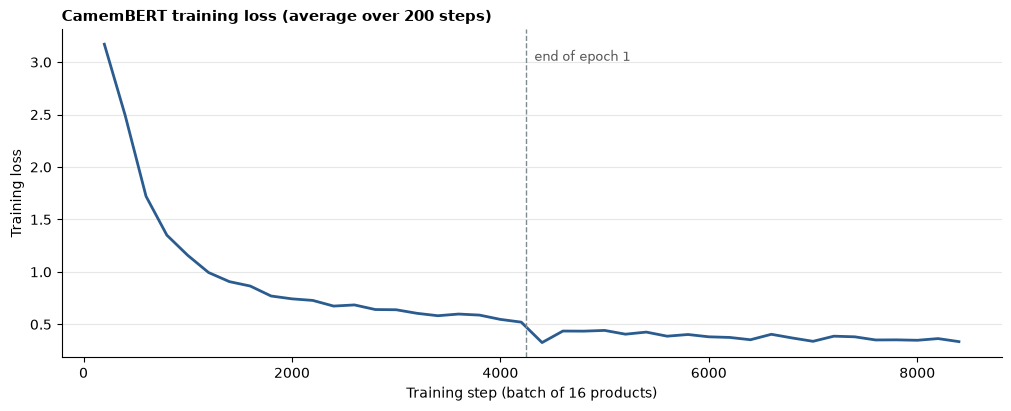

Epoch,Validation weighted F1,Validation macro F1
1,0.8518,0.8308
2,0.8764,0.8605


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

log = pd.read_csv("../data/processed/camembert_training_log.csv")
epoch_scores = pd.read_csv("../data/processed/camembert_epoch_scores.csv")

steps_per_epoch = 4246
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(log["step"], log["train_loss"], color="#2b5c8f", linewidth=2)
ax.axvline(steps_per_epoch, color="#7f8c8d", linestyle="--", linewidth=1)
ax.text(steps_per_epoch + 80, log["train_loss"].max() * 0.95, "end of epoch 1", color="#555555", fontsize=9)
ax.set_title("CamemBERT training loss (average over 200 steps)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Training step (batch of 16 products)")
ax.set_ylabel("Training loss")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

epoch_scores.rename(columns={"epoch": "Epoch", "weighted_f1": "Validation weighted F1", "macro_f1": "Validation macro F1"}).style.hide(axis="index").format(precision=4)

### Analysis

- The loss drops fast in the first 1000 steps: the model quickly learns the easy categories.
- It keeps going down slowly during epoch 2, so the model is still learning.
- Validation weighted F1 goes from 0.8518 after epoch 1 to 0.8764 after epoch 2. A third epoch may add a little more.

## 2. CamemBERT vs TF-IDF + SVM

Both are scored on the same 16984 validation products. The SVM is the optimised model from notebook 04.

In [2]:
validation = pd.read_csv("../data/processed/text_train_processed.csv")
validation = validation[validation["split"] == "validation"][["row_id", "prdtypecode"]]

camembert = pd.read_csv("../data/processed/camembert_validation_probabilities.csv")
svm = pd.read_csv("../data/processed/text_validation_probabilities.csv")
classes = np.array([int(c) for c in camembert.columns[1:]])

camembert = validation.merge(camembert, on="row_id")
svm = validation.merge(svm, on="row_id")
y_true = camembert["prdtypecode"].to_numpy()
pred_camembert = classes[camembert[[str(c) for c in classes]].to_numpy().argmax(axis=1)]
pred_svm = classes[svm[[str(c) for c in classes]].to_numpy().argmax(axis=1)]

summary = pd.DataFrame({
    "Model": ["TF-IDF + SVM", "CamemBERT"],
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in (pred_svm, pred_camembert)],
    "Macro F1": [f1_score(y_true, p, average="macro") for p in (pred_svm, pred_camembert)],
})
summary.style.hide(axis="index").format(precision=4)

Model,Weighted F1,Macro F1
TF-IDF + SVM,0.8430,0.8326
CamemBERT,0.8764,0.8605


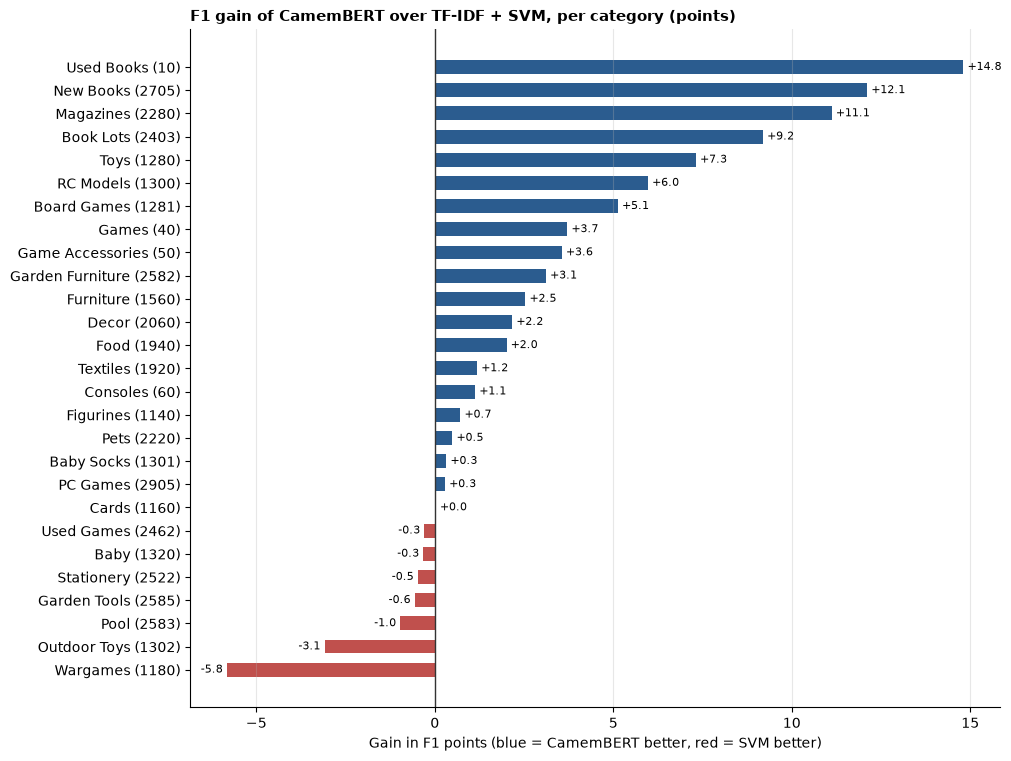

In [3]:
svm_scores = compute_per_class_metrics(y_true, pred_svm, classes)
camembert_scores = compute_per_class_metrics(y_true, pred_camembert, classes)

per_class = pd.DataFrame({
    "Code": classes,
    "Category": [CATEGORY_NAMES[c] for c in classes],
    "SVM F1": svm_scores["f1"],
    "CamemBERT F1": camembert_scores["f1"],
})
per_class["Gain"] = per_class["CamemBERT F1"] - per_class["SVM F1"]
per_class = per_class.sort_values("Gain")

fig, ax = plt.subplots(figsize=(10, 7.5), constrained_layout=True)
labels = [f"{n} ({c})" for n, c in zip(per_class["Category"], per_class["Code"])]
colors = ["#2b5c8f" if g >= 0 else "#c0504d" for g in per_class["Gain"]]
bars = ax.barh(labels, per_class["Gain"] * 100, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{g * 100:+.1f}" for g in per_class["Gain"]], padding=3, fontsize=8)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("F1 gain of CamemBERT over TF-IDF + SVM, per category (points)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Gain in F1 points (blue = CamemBERT better, red = SVM better)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

### Analysis

- CamemBERT beats TF-IDF + SVM by 3.3 points of weighted F1 (0.8764 against 0.8430) and 2.8 points of macro F1.
- The largest gains are on the book categories: Used Books +14.8 points, New Books +12.1, Magazines +11.1, Book Lots +9.2. These were the weakest categories for the SVM.
- Toys, RC Models and Board Games also gain 5 to 7 points.
- The SVM is still better on a few categories, mainly Wargames (-5.8) and Outdoor Toys (-3.1). These depend on rare, specific words (*warhammer*, *heroclix*, *trampoline*) that the SVM uses directly.

## 3. Most confused pairs

The 8 category pairs CamemBERT mixes up most often, with the number of errors for each model.

In [4]:
def confusion_counts(pred):
    errors = pd.DataFrame({"true": y_true, "pred": pred})
    errors = errors[errors["true"] != errors["pred"]]
    return errors.value_counts(["true", "pred"])

camembert_pairs = confusion_counts(pred_camembert)
svm_pairs = confusion_counts(pred_svm)

top = camembert_pairs.head(8)
pairs = pd.DataFrame({
    "True category": [f"{CATEGORY_NAMES[t]} ({t})" for t, _ in top.index],
    "Predicted as": [f"{CATEGORY_NAMES[p]} ({p})" for _, p in top.index],
    "CamemBERT errors": top.to_numpy(),
    "SVM errors": [svm_pairs.get(pair, 0) for pair in top.index],
})
print(f"Total errors: CamemBERT {(pred_camembert != y_true).sum()}, SVM {(pred_svm != y_true).sum()}")
pairs.style.hide(axis="index")

Total errors: CamemBERT 2088, SVM 2656


True category,Predicted as,CamemBERT errors,SVM errors
Used Books (10),New Books (2705),72,78
New Books (2705),Used Books (10),68,90
Board Games (1281),Toys (1280),64,91
Toys (1280),Board Games (1281),58,51
Book Lots (2403),Used Books (10),53,77
Furniture (1560),Decor (2060),45,44
Book Lots (2403),Magazines (2280),44,95
Used Books (10),Book Lots (2403),42,60


### Analysis

- CamemBERT makes 2088 errors against 2656 for the SVM (21% fewer).
- The same pairs are still the hardest: Used Books and New Books, Board Games and Toys, Book Lots and Used Books.
- CamemBERT halves the confusion between Book Lots and Magazines (44 errors against 95).

## Conclusion

- CamemBERT is the best text model: 0.8764 weighted F1 on validation.
- It helps most where the SVM was weakest, the book categories, because it reads words in context instead of counting them.
- The cost is training time: about 2 hours on a laptop GPU, against a few seconds for the SVM.